# Week 2 — Day 3: EDA Workflow

## Objective
Explore a sales dataset, identify data-quality issues, visualize distributions and correlations, and extract five business insights.

## Workflow
1. Load and profile the dataset.
2. Check missing values and duplicates.
3. Visualize numeric distributions.
4. Explore correlations with a heatmap.
5. Generate summary statistics and business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("cleaned_sales_data.csv")

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset loaded successfully
Rows: 10
Columns: 8


,sale_id,customer_name,product,category,region,amount,sale_date,discount
0,1,Ananya,Laptop,Electronics,South,55000.0,2026-09-01,0.10
1,2,Rahul,Phone,Electronics,North,25000.0,2026-09-02,0.05
2,3,Priya,Chair,Furniture,West,4500.0,2026-09-03,0.00
3,4,Arjun,Desk,Furniture,South,8000.0,2026-09-04,0.00
4,5,Meera,Headphones,Electronics,East,2000.0,2026-09-05,0.15


## 1. Dataset profiling

In [2]:
print("Dataset shape:", df.shape)
print("\\nColumn data types:")
display(df.dtypes.to_frame("Data Type"))
print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Dataset shape: (10, 8)
\nColumn data types:


,Data Type
sale_id,int64
customer_name,str
product,str
category,str
region,str
amount,float64
sale_date,str
discount,float64


\nMissing values:


,Missing Count
sale_id,0
customer_name,0
product,0
category,0
region,0
amount,0
sale_date,0
discount,0


\nDuplicate rows: 0
\nUnique values per column:


,Unique Values
sale_id,10
customer_name,10
product,10
category,3
region,4
amount,10
sale_date,10
discount,5


## 2. Summary statistics

In [3]:
numeric_df = df.select_dtypes(include="number")
if numeric_df.empty:
    print("No numeric columns found.")
else:
    summary = numeric_df.describe().T
    summary["median"] = numeric_df.median()
    summary["missing"] = numeric_df.isnull().sum()
    display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median,missing
sale_id,10.0,5.50,3.03,1.0,3.25,5.50,7.75,10.00,5.50,0
amount,10.0,13120.00,16757.03,50.0,2625.00,7250.00,16500.00,55000.00,7250.00,0
discount,10.0,0.04,0.05,0.0,0.00,0.02,0.07,0.15,0.02,0


## 3. Numeric distributions

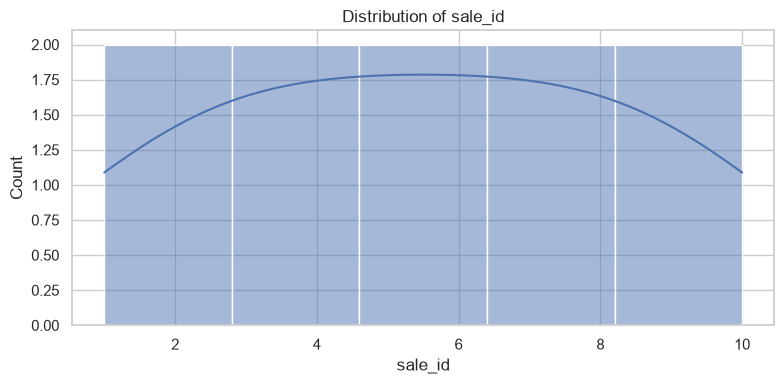

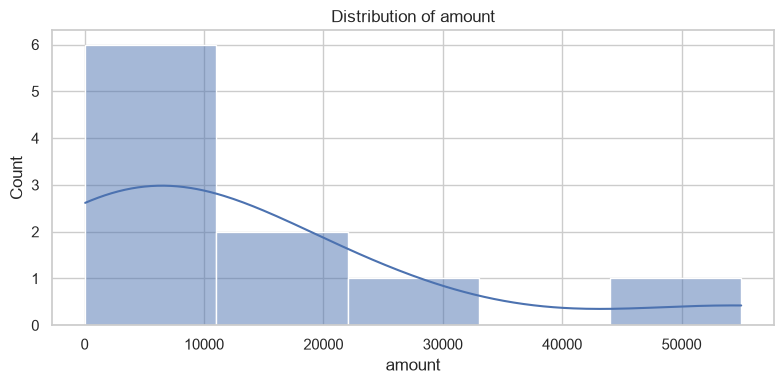

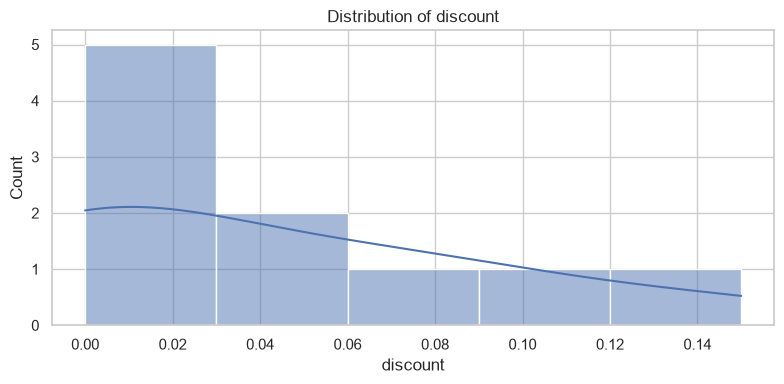

In [4]:
if numeric_df.empty:
    print("No numeric columns available for distribution plots.")
else:
    for column in numeric_df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(data=df, x=column, kde=True)
        plt.title(f"Distribution of {column}")
        plt.tight_layout()
        plt.show()

## 4. Correlation heatmap

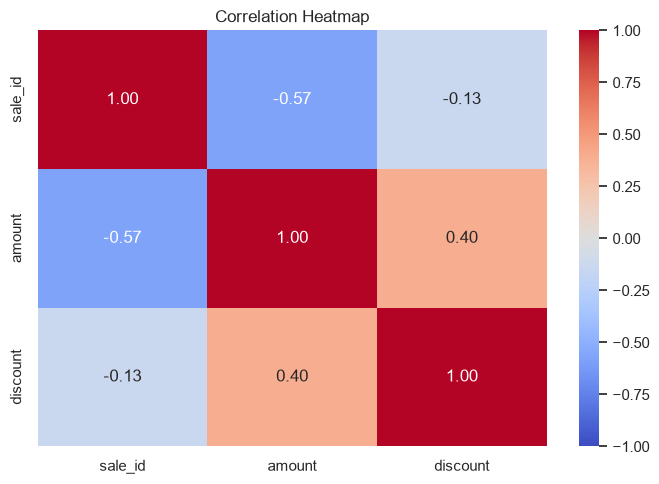

,sale_id,amount,discount
sale_id,1.00,-0.57,-0.13
amount,-0.57,1.00,0.40
discount,-0.13,0.40,1.00


In [5]:
if numeric_df.shape[1] < 2:
    print("At least two numeric columns are needed for a correlation heatmap.")
else:
    correlation = numeric_df.corr()
    plt.figure(figsize=(max(7, len(correlation.columns)), 5))
    sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f",
                vmin=-1, vmax=1)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
    display(correlation.round(2))

## 5. Outlier investigation

In [6]:
outlier_rows = []
for column in numeric_df.columns:
    values = numeric_df[column].dropna()
    if len(values) == 0:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((values < lower) | (values > upper)).sum()
    outlier_rows.append({
        "Column": column, "Lower Bound": lower,
        "Upper Bound": upper, "Potential Outliers": int(count)
    })
display(pd.DataFrame(outlier_rows))

,Column,Lower Bound,Upper Bound,Potential Outliers
0,sale_id,-3.50000,14.50000,0
1,amount,-18187.50000,37312.50000,1
2,discount,-0.10875,0.18125,0


## 6. Five business insights

In [7]:
insights = []

# Insight 1: Dataset size and data quality
insights.append(
    f"1. The dataset contains {df.shape[0]} rows and {df.shape[1]} columns, "
    f"with {int(df.isnull().sum().sum())} missing cells and "
    f"{int(df.duplicated().sum())} duplicate rows."
)

# Insight 2: Numeric column averages
if not numeric_df.empty:
    means = numeric_df.mean().dropna()
    if not means.empty:
        col = means.idxmax()
        insights.append(
            f"2. Among numeric columns, '{col}' has the highest mean "
            f"({means[col]:.2f}); review its business meaning and units."
        )
    else:
        insights.append("2. Numeric columns contain no usable averages.")
else:
    insights.append("2. No numeric columns are available for average analysis.")

# Insight 3: Highest variability
if not numeric_df.empty:
    stds = numeric_df.std().dropna()
    if not stds.empty:
        col = stds.idxmax()
        insights.append(
            f"3. '{col}' has the highest standard deviation "
            f"({stds[col]:.2f}), indicating comparatively high variability."
        )
    else:
        insights.append("3. Variability could not be calculated.")
else:
    insights.append("3. Variability analysis requires numeric columns.")

# Insight 4: Strongest correlation
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr()
    pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
    if not pairs.empty:
        pair = pairs.abs().idxmax()
        value = corr.loc[pair[0], pair[1]]
        insights.append(
            f"4. '{pair[0]}' and '{pair[1]}' have the strongest absolute "
            f"correlation ({value:.2f}). Correlation does not prove causation."
        )
    else:
        insights.append("4. No valid column pair was available for correlation.")
else:
    insights.append("4. At least two numeric columns are needed for correlation.")

# Insight 5: Most frequent category or most common numeric value
categorical = df.select_dtypes(exclude="number")
if not categorical.empty:
    col = categorical.nunique().idxmin()
    counts = df[col].value_counts(dropna=True)
    if not counts.empty:
        insights.append(
            f"5. The most frequent value in '{col}' is "
            f"'{counts.index[0]}' ({counts.iloc[0]} records). "
            "Consider whether this category dominates sales activity."
        )
    else:
        insights.append(f"5. Column '{col}' has no non-missing values.")
elif not numeric_df.empty:
    col = numeric_df.columns[0]
    insights.append(
        f"5. The median of '{col}' is {numeric_df[col].median():.2f}; "
        "compare it with the mean to assess possible skew."
    )
else:
    insights.append("5. No suitable column was found for a frequency insight.")

for insight in insights:
    print(insight)

1. The dataset contains 10 rows and 8 columns, with 0 missing cells and 0 duplicate rows.
2. Among numeric columns, 'amount' has the highest mean (13120.00); review its business meaning and units.
3. 'amount' has the highest standard deviation (16757.03), indicating comparatively high variability.
4. 'sale_id' and 'amount' have the strongest absolute correlation (-0.57). Correlation does not prove causation.
5. The most frequent value in 'category' is 'Electronics' (5 records). Consider whether this category dominates sales activity.


## 7. Conclusion and recommendations

Use the results above to:
- Investigate missing values and duplicates before further analysis.
- Review potential outliers before deciding whether they are errors or genuine events.
- Use the distribution charts to understand skew and unusual values.
- Investigate business relationships suggested by the correlation heatmap.
- Validate these findings with business context before making decisions.

**Note:** The five insights are generated from the dataset. Interpret each result using the actual column meanings before presenting it to stakeholders.